In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

print('Training shape: ' , train.shape)
print('Testing shape: ', test.shape)

Training shape:  (1460, 81)
Testing shape:  (1459, 80)


In [2]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [5]:
missing = train.isnull().sum()
missing[missing>0].sort_values()

Electrical         1
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
BsmtExposure      38
BsmtFinType2      38
GarageCond        81
GarageQual        81
GarageFinish      81
GarageYrBlt       81
GarageType        81
LotFrontage      259
FireplaceQu      690
MasVnrType       872
Fence           1179
Alley           1369
MiscFeature     1406
PoolQC          1453
dtype: int64

In [6]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [7]:
train[train["PoolQC"].notna()]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
197,198,75,RL,174.0,25419,Pave,NaN,Reg,Lvl,AllPub,...,512,Ex,GdPrv,NaN,0,3,2006,WD,Abnorml,235000
810,811,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,648,Fa,GdPrv,NaN,0,1,2006,WD,Normal,181000
1170,1171,80,RL,76.0,9880,Pave,NaN,Reg,Lvl,AllPub,...,576,Gd,GdPrv,NaN,0,7,2008,WD,Normal,171000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,...,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000
1386,1387,60,RL,80.0,16692,Pave,NaN,IR1,Lvl,AllPub,...,519,Fa,MnPrv,TenC,2000,7,2006,WD,Normal,250000
1423,1424,80,RL,NaN,19690,Pave,NaN,IR1,Lvl,AllPub,...,738,Gd,GdPrv,NaN,0,8,2006,WD,Alloca,274970


In [8]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [44]:
train.isna().sum().sort_values(ascending=False).head(15)  

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
dtype: int64

<Axes: xlabel='SalePrice', ylabel='Count'>

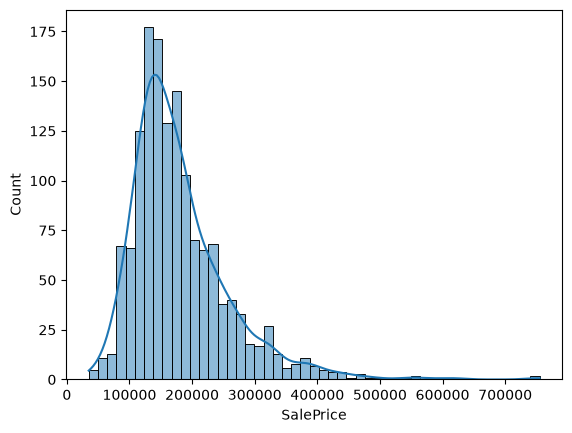

In [9]:
sns.histplot(train['SalePrice'], kde=True)

<Axes: xlabel='SalePrice', ylabel='Count'>

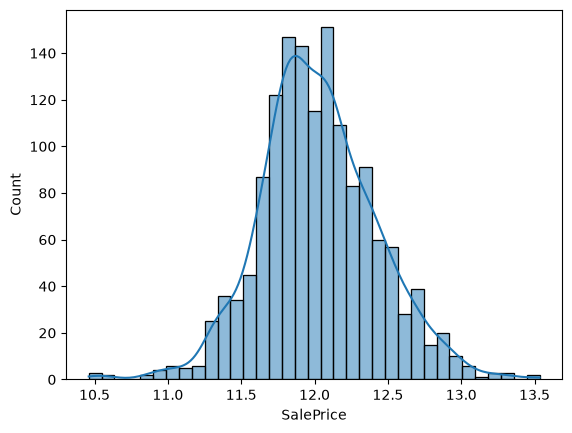

In [10]:
sns.histplot(np.log1p(train["SalePrice"]), kde=True)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

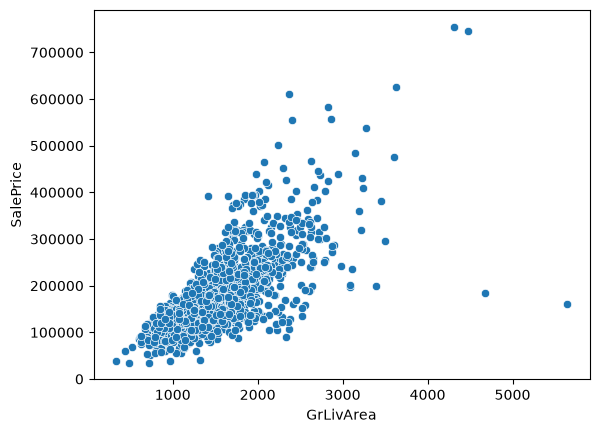

In [11]:
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice")

In [34]:
train[(train["GrLivArea"]>4000) & (train["SalePrice"]<400000)][["Id", "GrLivArea", "SalePrice", "OverallQual", "YearBuilt", "Neighborhood"]]

,Id,GrLivArea,SalePrice,OverallQual,YearBuilt,Neighborhood
523,524,4676,184750,10,2007,Edwards
1298,1299,5642,160000,10,2008,Edwards


In [39]:
train[train["OverallQual"]==10]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
58,59,60,RL,66.0,13682,Pave,NaN,IR2,HLS,AllPub,...,0,NaN,NaN,NaN,0,10,2006,New,Partial,438780
185,186,75,RM,90.0,22950,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,6,2006,WD,Normal,475000
224,225,20,RL,103.0,13472,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,386250
389,390,60,RL,96.0,12474,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2008,New,Partial,426000
440,441,20,RL,105.0,15431,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,WD,Normal,555000
515,516,20,RL,94.0,12220,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,New,Partial,402861
523,524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,...,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
583,584,75,RM,75.0,13500,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,325000
591,592,60,RL,97.0,13478,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,ConLI,Normal,451950
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000


<Axes: xlabel='OverallQual', ylabel='SalePrice'>

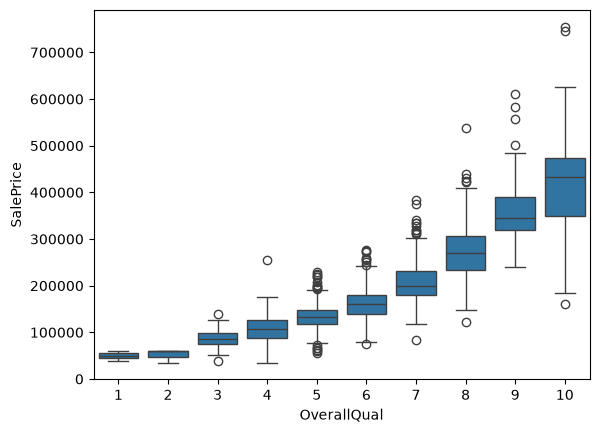

In [13]:
sns.boxplot(data=train, x="OverallQual", y="SalePrice")

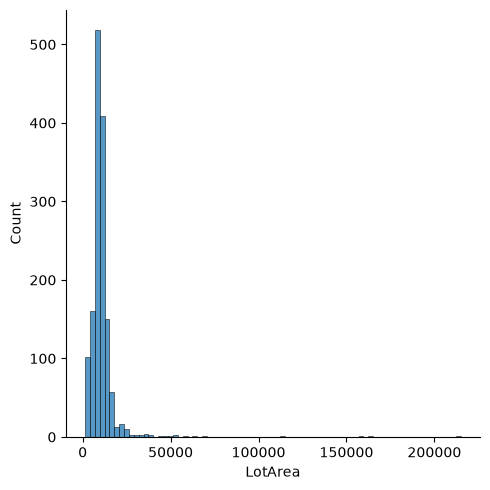

In [24]:
sns.displot(data=train, x="LotArea")

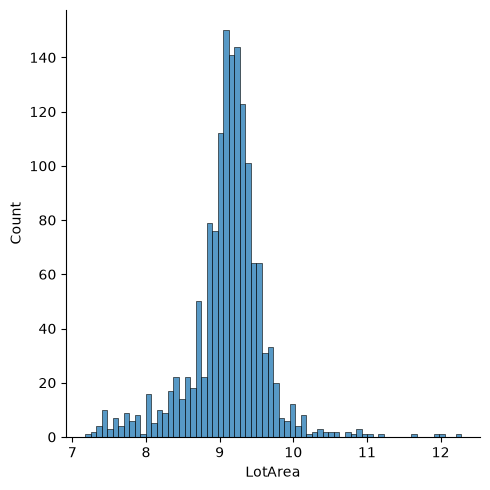

In [26]:
sns.displot(np.log1p(train["LotArea"]))

In [14]:
corr = (train.select_dtypes(include='number').corr()["SalePrice"].sort_values(ascending=False))
corr

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

We notice that OverallQual is probably one of the most major facts in the sales price derivation. Also, Living area and garage cars influence it considerably as well.

In [15]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [16]:
x = train.drop(columns=['SalePrice', 'Id'])
y = np.log1p(train['SalePrice'])
x_test = test.drop(columns=['Id'])
print(x_test.shape, x.shape)

(1459, 79) (1460, 79)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

In [18]:
numeric_features = x.select_dtypes(include='number').columns
categorical_features = x.select_dtypes(exclude='number').columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='median')),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy='most_frequent')),
    ("encoder", OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


In [22]:
from sklearn.model_selection import KFold
kf = KFold(n_splits = 5, shuffle=True, random_state=2)

In [23]:
from sklearn.model_selection import cross_val_score
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])
scores = cross_val_score(model, x , y, cv=kf, scoring="neg_root_mean_squared_error")
rmse_Scores = -scores
print("Fold RMSE:", rmse_Scores)
print("Mean CV RMSE:", rmse_Scores.mean())
print("Standard deviation:", rmse_Scores.std())

Fold RMSE: [0.12546433 0.22079105 0.13028161 0.13825846 0.11808322]
Mean CV RMSE: 0.14657573286080966
Standard deviation: 0.03768316283541972


In [20]:
model.fit(x,y)
predictions = model.predict(x_test)
predictions = np.expm1(predictions)

submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": predictions
})

submission.to_csv("../submissions/submission_baseline.csv", index=False)
submission.head()

,Id,SalePrice
0,1461,114305.659265
1,1462,145494.323577
2,1463,170683.753695
3,1464,192630.078501
4,1465,198251.742864


In [40]:
train_clean = train[train["GrLivArea"]<=4000].copy()
x_clean = train_clean.drop(columns = ["Id", "SalePrice"])
y_clean = np.log1p(train_clean["SalePrice"])

In [42]:
score_clean = cross_val_score(model, x_clean, y_clean, cv=kf, scoring="neg_root_mean_squared_error")
print(rmse_Scores.mean())
print(-1 * score_clean.mean())
print(-1 * score_clean)

0.14657573286080966
0.11670693669784042
[0.12086224 0.10506384 0.12009772 0.11821542 0.11929547]


In [52]:
categorical_pipeline2 = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="None"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])
numeric_features = x_clean.select_dtypes(include=["number"]).columns
categorical_features = x_clean.select_dtypes(exclude=["number"]).columns
numeric_pipeline2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
preprocessor2 = ColumnTransformer([
    ("num", numeric_pipeline2, numeric_features),
    ("cat", categorical_pipeline2, categorical_features)
])

In [53]:
model2 = Pipeline([
    ("preprocessor", preprocessor2),
    ("regressor", Ridge(alpha=10.0))
])

score2 =-1 * cross_val_score(model2, x_clean, y_clean, cv=kf, scoring="neg_root_mean_squared_error")
print(-1 * scores)
print(score2)
print(-1 * scores.mean())
print(score2.mean())

[0.12546433 0.22079105 0.13028161 0.13825846 0.11808322]
[0.12002793 0.10538555 0.12055332 0.11882638 0.11949298]
0.14657573286080966
0.11685723035197756


In [ ]:
skewness = x_clean.select_dtypes(include="number").skew()
skewness = skewness.sort_values(ascending=False)
skewness.head(15)

MiscVal          24.443364
PoolArea         17.522613
LotArea          12.587561
3SsnPorch        10.289866
LowQualFinSF      8.998564
KitchenAbvGr      4.481366
BsmtFinSF2        4.248587
BsmtHalfBath      4.128967
ScreenPorch       4.115641
EnclosedPorch     3.084454
MasVnrArea        2.648987
OpenPorchSF       2.339846
WoodDeckSF        1.551271
LotFrontage       1.536435
MSSubClass        1.406366
dtype: float64

In [66]:
from sklearn.preprocessing import FunctionTransformer
log_features = list(skewness[skewness>2].index)
rest_numeric_features = [col for col in numeric_features if col not in log_features]
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler())
])
preprocessor3 = ColumnTransformer([
    ("num", numeric_pipeline, rest_numeric_features),
    ("log", log_pipeline, log_features),
    ("cat", categorical_pipeline2, categorical_features)
])
print(log_features)

['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'KitchenAbvGr', 'BsmtFinSF2', 'BsmtHalfBath', 'ScreenPorch', 'EnclosedPorch', 'MasVnrArea', 'OpenPorchSF']


In [67]:
model3 = Pipeline([
    ("preprocessor", preprocessor3),
    ("regressor", Ridge(alpha=10.0))
])
score3 = -cross_val_score(model3, x_clean, y_clean, cv=kf, scoring = "neg_root_mean_squared_error")
print(score3)
print(score3.mean())

[0.11738504 0.10265097 0.11671033 0.11742654 0.11861531]
0.11455763814397106
